In [1]:
import sys
sys.path.append('/home/smarci/python_libs')

import flap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import correlate
from scipy.optimize import curve_fit
from poloidal_flow import CorrelationConfig, CorrelationAnalysis, ABESConfig, ABESDataReader

defl0 = flap.load('../pickled_shot_data/20250409.046_detrend_defl0.pkl')
defl1 = flap.load('../pickled_shot_data/20250409.046_detrend_defl1.pkl')

t = 6.5

defl0_sl = defl0.slice_data(
    slicing = {'Time': flap.Intervals(t, t + 1)}
)

defl1_sl = defl1.slice_data(
    slicing = {'Time': flap.Intervals(t, t + 1)}
)

INIT flap storage
Importing flap_w7x_abes
Importing w7x_webapi


In [2]:
xconfig = CorrelationConfig('parabola', 1, xcorr_interval=100, xcorr_time_lag_interval=(-500e-6, 500e-6))
anal = CorrelationAnalysis(defl0_sl, defl1_sl, xconfig)

In [3]:
time_lag_axis = np.linspace(-500, 500, 51)

In [4]:
acf_0 = []
acf_1 = []

for ch in range(1, 41):
    
    defl0_sl_ch = defl0.slice_data(
        slicing = {'Channel number': ch}
    )  

    defl1_sl_ch = defl1.slice_data(
        slicing = {'Channel number': ch}
    )
    
    a0 = anal.acf_window_single(defl0_sl_ch)
    a1 = anal.acf_window_single(defl1_sl_ch)
    
    acf_0.append(a0.data)
    acf_1.append(a1.data)

Interval 1/100
Interval 2/100
Interval 3/100
Interval 4/100
Interval 5/100
Interval 6/100
Interval 7/100
Interval 8/100
Interval 9/100
Interval 10/100
Interval 11/100
Interval 12/100
Interval 13/100
Interval 14/100
Interval 15/100
Interval 16/100
Interval 17/100
Interval 18/100
Interval 19/100
Interval 20/100
Interval 21/100
Interval 22/100
Interval 23/100
Interval 24/100
Interval 25/100
Interval 26/100
Interval 27/100
Interval 28/100
Interval 29/100
Interval 30/100
Interval 31/100
Interval 32/100
Interval 33/100
Interval 34/100
Interval 35/100
Interval 36/100
Interval 37/100
Interval 38/100
Interval 39/100
Interval 40/100
Interval 41/100
Interval 42/100
Interval 43/100
Interval 44/100
Interval 45/100
Interval 46/100
Interval 47/100
Interval 48/100
Interval 49/100
Interval 50/100
Interval 51/100
Interval 52/100
Interval 53/100
Interval 54/100
Interval 55/100
Interval 56/100
Interval 57/100
Interval 58/100
Interval 59/100
Interval 60/100
Interval 61/100
Interval 62/100
Interval 63/100
I

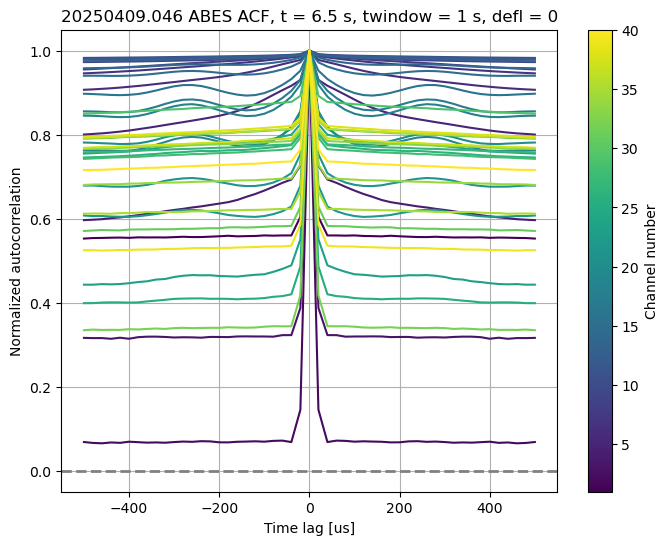

In [5]:
norm = mpl.colors.Normalize(vmin = 1, vmax = 40)
cmap = mpl.colormaps['viridis']

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig, ax = plt.subplots(figsize = (8, 6))
for (i, ch) in enumerate(range(1, 41)):
    ax.plot(time_lag_axis, acf_0[i], color=cmap(norm(ch)))

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Channel number')
ax.set_title(f'20250409.046 ABES ACF, t = {t} s, twindow = 1 s, defl = 0')
ax.set_xlabel('Time lag [us]')
ax.set_ylabel('Normalized autocorrelation')
ax.axhline(0, ls = '--', lw = 2, c = 'gray')
ax.grid()

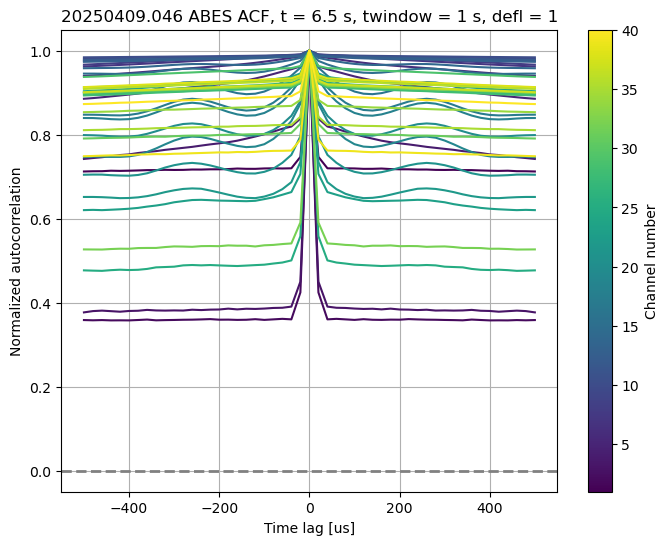

In [6]:
fig, ax = plt.subplots(figsize = (8, 6))
for (i, ch) in enumerate(range(1, 41)):
    ax.plot(time_lag_axis, acf_1[i], color=cmap(norm(ch)))

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Channel number')
ax.set_title(f'20250409.046 ABES ACF, t = {t} s, twindow = 1 s, defl = 1')
ax.set_xlabel('Time lag [us]')
ax.set_ylabel('Normalized autocorrelation')
ax.axhline(0, ls = '--', lw = 2, c = 'gray')
ax.grid()

In [7]:
acf0_arr = np.array(acf_0)
acf1_arr = np.array(acf_1)

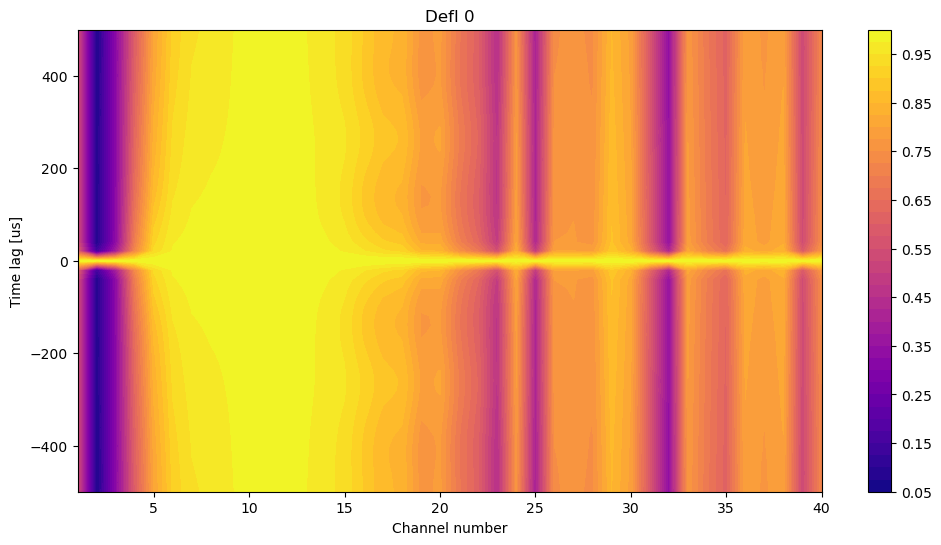

In [8]:
plt.figure(figsize = (12, 6))

plt.title('Defl 0')
plt.ylabel('Time lag [us]')
plt.xlabel('Channel number')
plt.contourf(np.arange(1, 41), time_lag_axis, acf0_arr.T, levels = 40, cmap = 'plasma')
plt.colorbar()

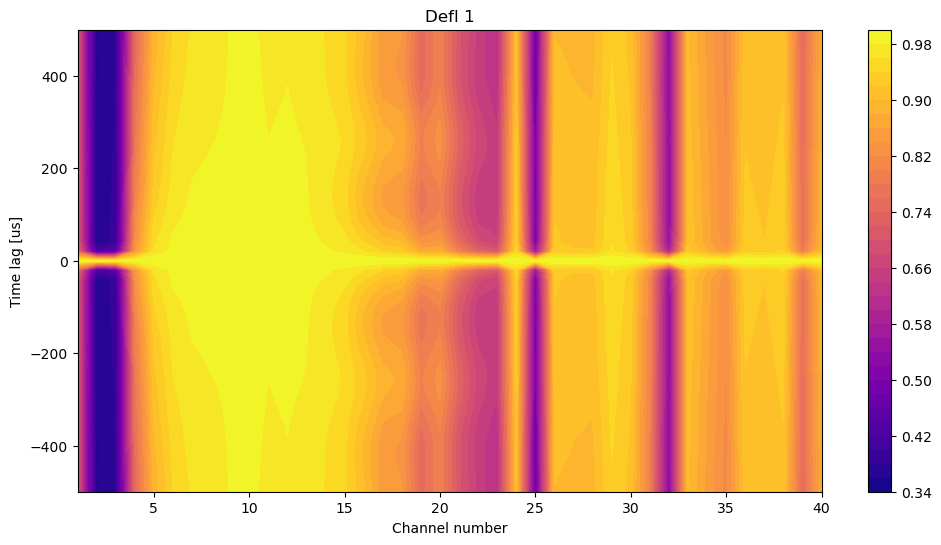

In [9]:
plt.figure(figsize = (12, 6))

plt.title('Defl 1')
plt.ylabel('Time lag [us]')
plt.xlabel('Channel number')
plt.contourf(np.arange(1, 41), time_lag_axis, acf1_arr.T, levels = 40, cmap = 'plasma')
plt.colorbar()